## Kelompok 5 - AI (B):
1. Rakharestna Razan P - 2206053215
2. Muhamad Jason T - 2206050415
3. Muhammad Izzudin Al Azzam - 2206810345
4. Saka Mayza Leksono - 2206824880
5. David Sitohang - 2206053114

##### Library dependensi yang diperlukan:
1. PyTorch
2. openpyxl 
3. matplotlib
4. pandas
5. scikit-learn
6. numpy
7. tqdm

Install dengan python-pip
``` bash
pip install pytorch tqdm matplotlib pandas seaborn scikit-learn numpy
```
Minimal Menjalankan Semua Cell Kira-kira 25 Menit

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob
import random
import os
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable

from tqdm.notebook import tqdm
from math import sqrt
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error


Using device: cuda


Kode ini menggunakan dataset CALCE dengan sub-dataset CS2_35 hingga CS2_38 dengan kondisi pengujian dilakukan pada suhu 1°C dengan metode pengisian menggunakan mode arus konstan (CC) hingga tegangan baterai mencapai 4,2V, kemudian dilanjutkan dengan mode tegangan konstan (CV) hingga arus pengisian turun menjadi 20mA. Proses pengosongan dilakukan dengan mode arus konstan (CC) hingga tegangan baterai turun ke 2,7V. Sebelum analisis data, beberapa outlier dalam data perlu dihilangkan.

In [2]:
def drop_outlier(array,count,bins):
    index = []
    range_ = np.arange(1,count,bins)
    for i in range_[:-1]:
        array_lim = array[i:i+bins]
        sigma = np.std(array_lim)
        mean = np.mean(array_lim)
        th_max,th_min = mean + sigma*2, mean - sigma*2
        idx = np.where((array_lim < th_max) & (array_lim > th_min))
        idx = idx[0] + i
        index.extend(list(idx))
    return np.array(index)

#### Tahap 1 : Load Data
###### Waktu agak lama sekitar 4-6 menit tergantung PC

In [3]:
Battery_list = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']

dir_path = 'dataset/'
Battery = {}
for name in Battery_list:
    print('Load Dataset ' + name + ' ...')
    path = glob.glob(dir_path + name + '/*.xlsx')
    dates = []
    for p in path:
        df = pd.read_excel(p, sheet_name=1)
        print('Load ' + str(p) + ' ...')
        dates.append(df['Date_Time'][0])
    idx = np.argsort(dates)
    path_sorted = np.array(path)[idx]
    
    count = 0
    discharge_capacities = []
    health_indicator = []
    internal_resistance = []
    CCCT = []
    CVCT = []
    for p in path_sorted:
        df = pd.read_excel(p,sheet_name=1)
        print('Load ' + str(p) + ' ...')
        cycles = list(set(df['Cycle_Index']))
        for c in cycles:
            df_lim = df[df['Cycle_Index'] == c]
            #Charging
            df_c = df_lim[(df_lim['Step_Index'] == 2)|(df_lim['Step_Index'] == 4)]
            c_v = df_c['Voltage(V)']
            c_c = df_c['Current(A)']
            c_t = df_c['Test_Time(s)']
            #CC or CV
            df_cc = df_lim[df_lim['Step_Index'] == 2]
            df_cv = df_lim[df_lim['Step_Index'] == 4]
            CCCT.append(np.max(df_cc['Test_Time(s)'])-np.min(df_cc['Test_Time(s)']))
            CVCT.append(np.max(df_cv['Test_Time(s)'])-np.min(df_cv['Test_Time(s)']))

            #Discharging
            df_d = df_lim[df_lim['Step_Index'] == 7]
            d_v = df_d['Voltage(V)']
            d_c = df_d['Current(A)']
            d_t = df_d['Test_Time(s)']
            d_im = df_d['Internal_Resistance(Ohm)']

            if(len(list(d_c)) != 0):
                time_diff = np.diff(list(d_t))
                d_c = np.array(list(d_c))[1:]
                discharge_capacity = time_diff*d_c/3600 # Q = A*h
                discharge_capacity = [np.sum(discharge_capacity[:n]) for n in range(discharge_capacity.shape[0])]
                discharge_capacities.append(-1*discharge_capacity[-1])

                dec = np.abs(np.array(d_v) - 3.8)[1:]
                start = np.array(discharge_capacity)[np.argmin(dec)]
                dec = np.abs(np.array(d_v) - 3.4)[1:]
                end = np.array(discharge_capacity)[np.argmin(dec)]
                health_indicator.append(-1 * (end - start))

                internal_resistance.append(np.mean(np.array(d_im)))
                count += 1

    discharge_capacities = np.array(discharge_capacities)
    health_indicator = np.array(health_indicator)
    internal_resistance = np.array(internal_resistance)
    CCCT = np.array(CCCT)
    CVCT = np.array(CVCT)
    
    idx = drop_outlier(discharge_capacities, count, 40)
    df_result = pd.DataFrame({'cycle':np.linspace(1,idx.shape[0],idx.shape[0]),
                              'capacity':discharge_capacities[idx],
                              'SoH':health_indicator[idx],
                              'resistance':internal_resistance[idx],
                              'CCCT':CCCT[idx],
                              'CVCT':CVCT[idx]})
    Battery[name] = df_result

Load Dataset CS2_35 ...
Load dataset/CS2_35\CS2_35_10_15_10.xlsx ...
Load dataset/CS2_35\CS2_35_10_22_10.xlsx ...
Load dataset/CS2_35\CS2_35_10_29_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_01_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_08_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_23_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_24_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_06_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_13_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_20_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_23_10.xlsx ...
Load dataset/CS2_35\CS2_35_1_10_11.xlsx ...
Load dataset/CS2_35\CS2_35_1_18_11.xlsx ...
Load dataset/CS2_35\CS2_35_1_24_11.xlsx ...
Load dataset/CS2_35\CS2_35_1_28_11.xlsx ...
Load dataset/CS2_35\CS2_35_2_10_11.xlsx ...
Load dataset/CS2_35\CS2_35_2_4_11.xlsx ...
Load dataset/CS2_35\CS2_35_8_17_10.xlsx ...
Load dataset/CS2_35\CS2_35_8_18_10.xlsx ...
Load dataset/CS2_35\CS2_35_8_19_10.xlsx ...
Load dataset/CS2_35\CS2_35_8_30_10.xlsx ...
Load dataset/CS2_35\CS2_35_9_21_10.xlsx ..


 Battery: CS2_35

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 882 entries, 0 to 881
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       882 non-null    float64
 1   capacity    882 non-null    float64
 2   SoH         882 non-null    float64
 3   resistance  882 non-null    float64
 4   CCCT        882 non-null    float64
 5   CVCT        864 non-null    float64
dtypes: float64(6)
memory usage: 41.5 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  882.000000  882.000000  882.000000  882.000000   882.000000   
mean   441.500000    0.855104    0.616943    0.099438  4717.136205   
std    254.755765    0.208222    0.185902    0.009659  1482.285660   
min      1.000000    0.256677    0.100836    0.085018     0.000000   
25%    221.250000    0.742563    0.550114    0.092968  3874.282920   
50%    441.500000    0.951852    0.706010    

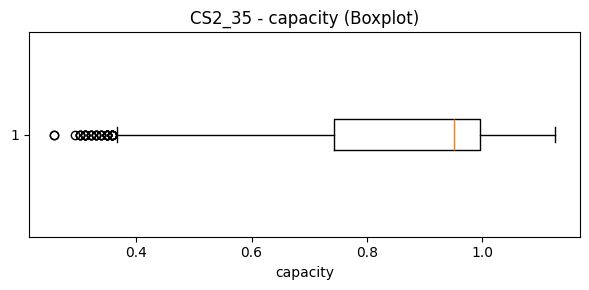

SoH: 85 outliers


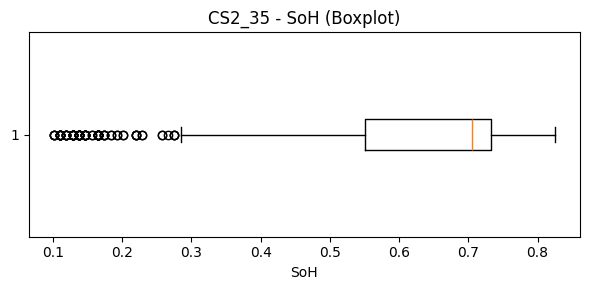

resistance: 69 outliers


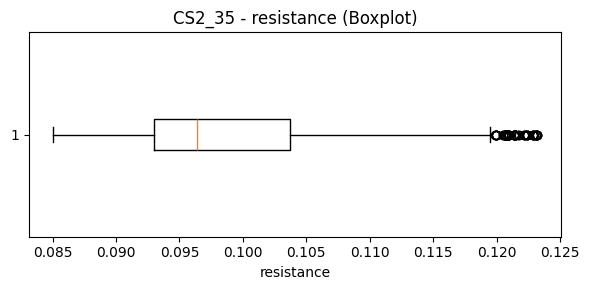

CCCT: 12 outliers


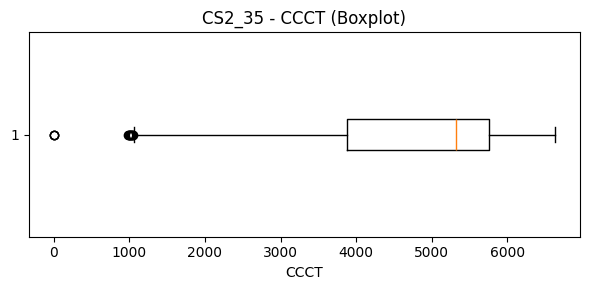

CVCT: 11 outliers


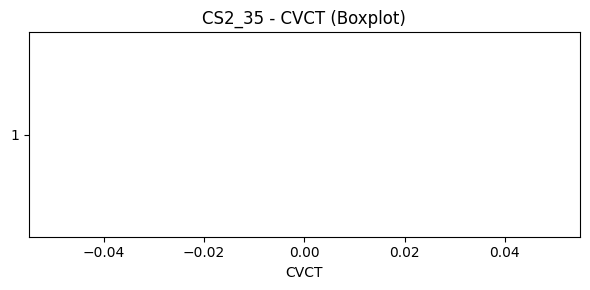


 Battery: CS2_36

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 936 entries, 0 to 935
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       936 non-null    float64
 1   capacity    936 non-null    float64
 2   SoH         936 non-null    float64
 3   resistance  936 non-null    float64
 4   CCCT        936 non-null    float64
 5   CVCT        923 non-null    float64
dtypes: float64(6)
memory usage: 44.0 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  936.000000  936.000000  936.000000  936.000000   936.000000   
mean   468.500000    0.822947    0.585501    0.096466  4539.825729   
std    270.344225    0.259221    0.219250    0.011233  1780.849907   
min      1.000000    0.137548    0.045847    0.082047   119.560680   
25%    234.750000    0.733678    0.541084    0.088385  3893.459239   
50%    468.500000    0.925265    0.678639    

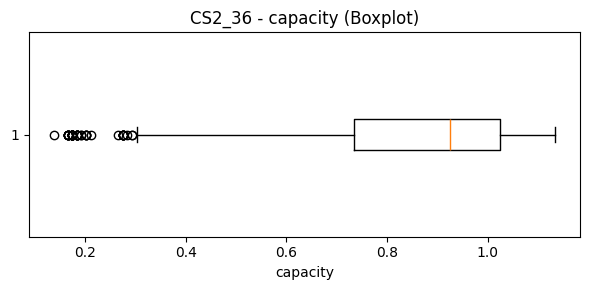

SoH: 126 outliers


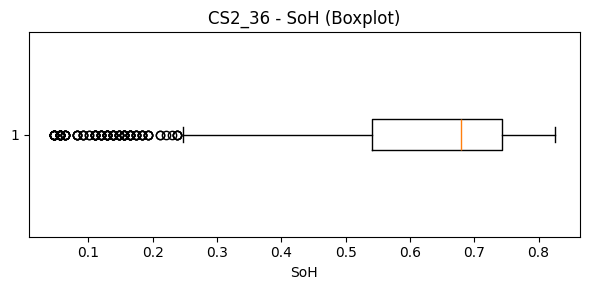

resistance: 72 outliers


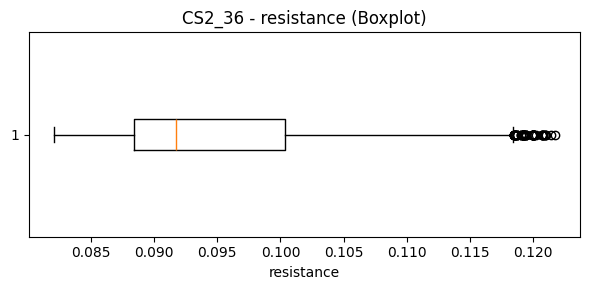

CCCT: 36 outliers


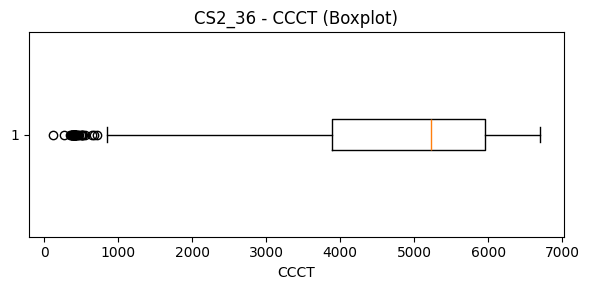

CVCT: 12 outliers


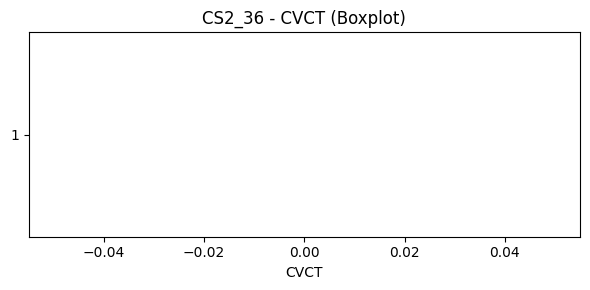


 Battery: CS2_37

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 972 entries, 0 to 971
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       972 non-null    float64
 1   capacity    972 non-null    float64
 2   SoH         972 non-null    float64
 3   resistance  972 non-null    float64
 4   CCCT        972 non-null    float64
 5   CVCT        958 non-null    float64
dtypes: float64(6)
memory usage: 45.7 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  972.000000  972.000000  972.000000  972.000000   972.000000   
mean   486.500000    0.847870    0.610755    0.097018  4685.225712   
std    280.736531    0.207910    0.181729    0.009433  1461.793584   
min      1.000000    0.201708    0.055010    0.084628     0.000000   
25%    243.750000    0.777747    0.568463    0.090324  4148.924058   
50%    486.500000    0.933851    0.687622    

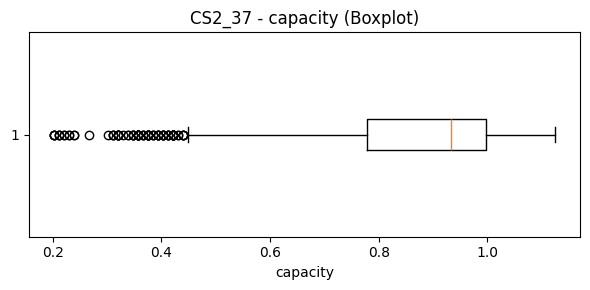

SoH: 109 outliers


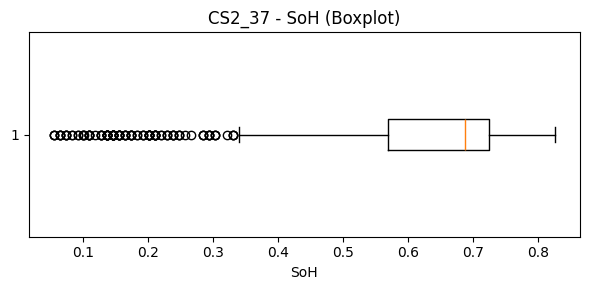

resistance: 94 outliers


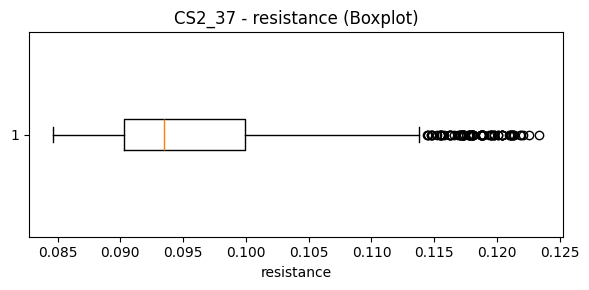

CCCT: 80 outliers


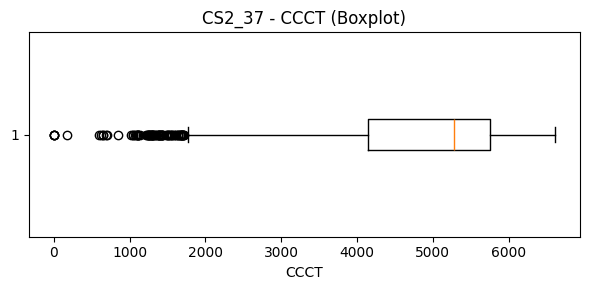

CVCT: 14 outliers


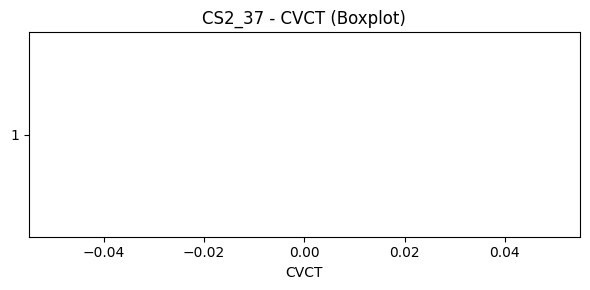


 Battery: CS2_38

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 996 entries, 0 to 995
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       996 non-null    float64
 1   capacity    996 non-null    float64
 2   SoH         996 non-null    float64
 3   resistance  996 non-null    float64
 4   CCCT        996 non-null    float64
 5   CVCT        986 non-null    float64
dtypes: float64(6)
memory usage: 46.8 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  996.000000  996.000000  996.000000  996.000000   996.000000   
mean   498.500000    0.853773    0.621669    0.107146  4678.212726   
std    287.664735    0.204206    0.187294    0.019952  1454.386030   
min      1.000000    0.284185    0.082504    0.088015     0.000000   
25%    249.750000    0.806699    0.595850    0.095687  4393.711393   
50%    498.500000    0.941821    0.696627    

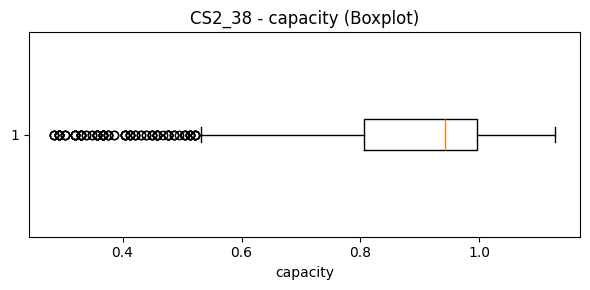

SoH: 144 outliers


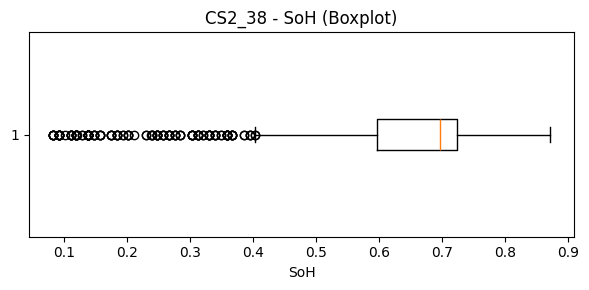

resistance: 86 outliers


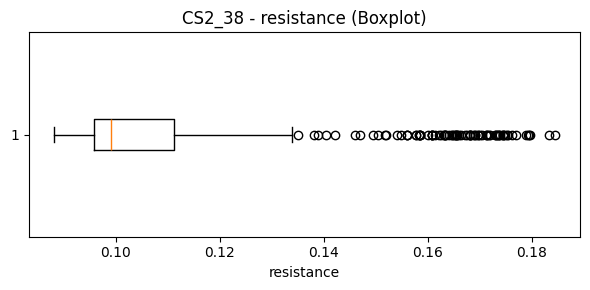

CCCT: 127 outliers


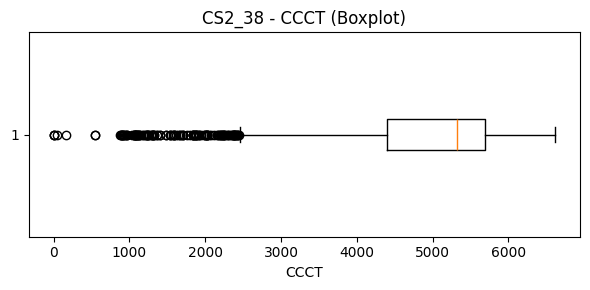

CVCT: 20 outliers


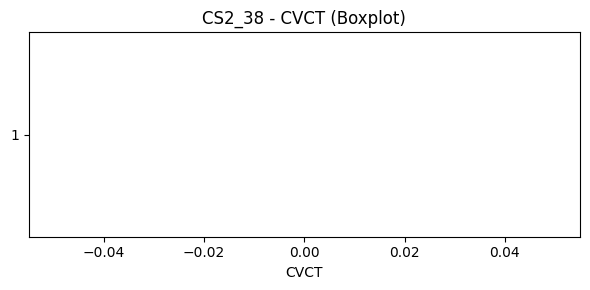

In [4]:
def check_outliers_and_info(Battery):
    for name, df in Battery.items():
        print(f"\n Battery: {name}")
        print("\nData Info :")
        print(df.info())

        print("\nDescriptive Statistics :")
        print(df.describe())

        print("\nOutlier Detection (IQR Method) :")
        for column in ['capacity', 'SoH', 'resistance', 'CCCT', 'CVCT']:
            Q1 = df[column].quantile(0.25)
            Q3 = df[column].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

            print(f"{column}: {len(outliers)} outliers")

            # Optional: Plot boxplot
            plt.figure(figsize=(6, 3))
            plt.boxplot(df[column], vert=False)
            plt.title(f'{name} - {column} (Boxplot)')
            plt.xlabel(column)
            plt.tight_layout()
            plt.show()
check_outliers_and_info(Battery)

#### Tahap 2 : Melihat Degradasi Kapasitas dari 4 Baterai

##### Dalam analisis baterai lithium, parameter utama yang diperhatikan adalah kapasitas, arus, dan tegangan, dengan fokus utama pada pemodelan kurva penurunan kapasitas selama siklus discharge untuk memprediksi umur baterai.


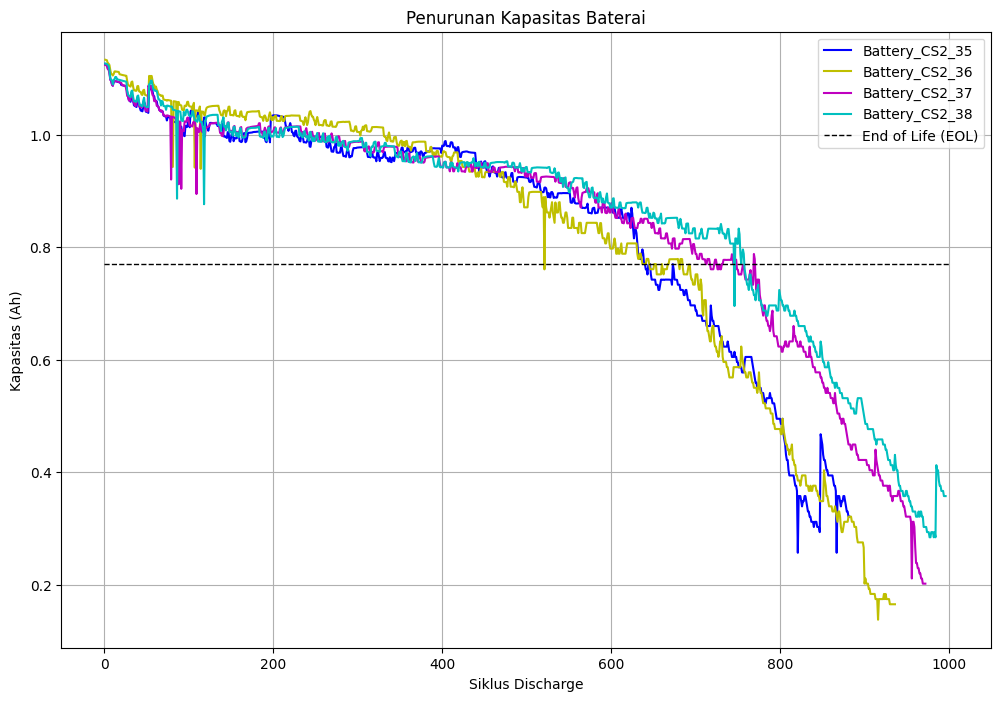

In [5]:
Rated_Capacity = 1.1 # Kapasitas terukur baterai menurun 30%, dari 1,1 Ahr menjadi 0,77 Ahr, sehingga 1,1 menjadi standar End Of Life (EOF)
fig, ax = plt.subplots(1, figsize=(12, 8))
color_list = ['b-', 'y-', 'm-', 'c-']
for name,color in zip(Battery_list, color_list):
    battery = Battery[name]
    ax.plot(battery['cycle'], battery['capacity'], color, label='Battery_'+name)
plt.plot([-1,1000],[Rated_Capacity*0.7, Rated_Capacity*0.7], c='black', lw=1, ls='--', label='End of Life (EOL)')  # 
ax.set(xlabel='Siklus Discharge', ylabel='Kapasitas (Ah)', title='Penurunan Kapasitas Baterai')
plt.legend()
plt.grid()
plt.savefig("./Gambar/Degradasi Kapasitas Baterai (Semua Baterai).png")
plt.show()

#### Tahap 3 : Menggunakan Gauss Fitting untuk Melihat Loss

In [6]:
def setup_seed(seed):
    np.random.seed(seed)  # Numpy module.
    random.seed(seed)  # Python random module.
    os.environ['PYTHONHASHSEED'] = str(seed) 
    torch.manual_seed(seed) # Set random seed for CPU
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed) # Set the random seed for the current GPU
        torch.cuda.manual_seed_all(seed) 
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

In [7]:
class Net_Gauss(nn.Module):
    def __init__(self, k=3, eps=1e-6):
        super(Net_Gauss, self).__init__()
        self.eps = eps
        self.w = torch.nn.Parameter(torch.randn((3, k)), requires_grad=True)
        
    def forward(self, x): 
        out = 0
        for i in range(k):
            out += self.w[0, i] * torch.exp(-torch.pow((x - self.w[1, i])/(self.w[2, i] + self.eps), 2)) 
        return out

In [8]:
def train_Gauss(data, k=3, lr=1e-4, stop=1e-3, epochs=100000, device=device):  
    model = Net_Gauss(k=k)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    loss_list = []
    epoch = 0
    while True:
        train_data = np.random.permutation(data)
        x, y = train_data[:,0], train_data[:,1]
        X, y = np.reshape(x, (-1, 1)).astype(np.float32), np.reshape(y, (-1, 1)).astype(np.float32)
        X, y = Variable(torch.from_numpy(X)).to(device), Variable(torch.from_numpy(y)).to(device)
        y_ = model(X)
        loss = criterion(y_, y)
        # print(loss.detach().numpy())
        optimizer.zero_grad()              
        loss.backward()                    # backpropagation
        optimizer.step()                   
        
        if epoch % 100 == 0:
            loss_list.append(loss.detach().cpu().numpy())
            
        if (loss.detach().cpu().numpy() < stop) or (epoch > epochs):
            break
            
        epoch +=1

    return model, loss_list

def predict(model, x, device=device):
    x = np.array(x).astype(np.float32)
    x = torch.from_numpy(x).to(device)
    model.eval()
    with torch.no_grad():
        y_ = model(x)
    return y_.detach().cpu().numpy()


Training on: CS2_35

Training on: CS2_36

Training on: CS2_37

Training on: CS2_38


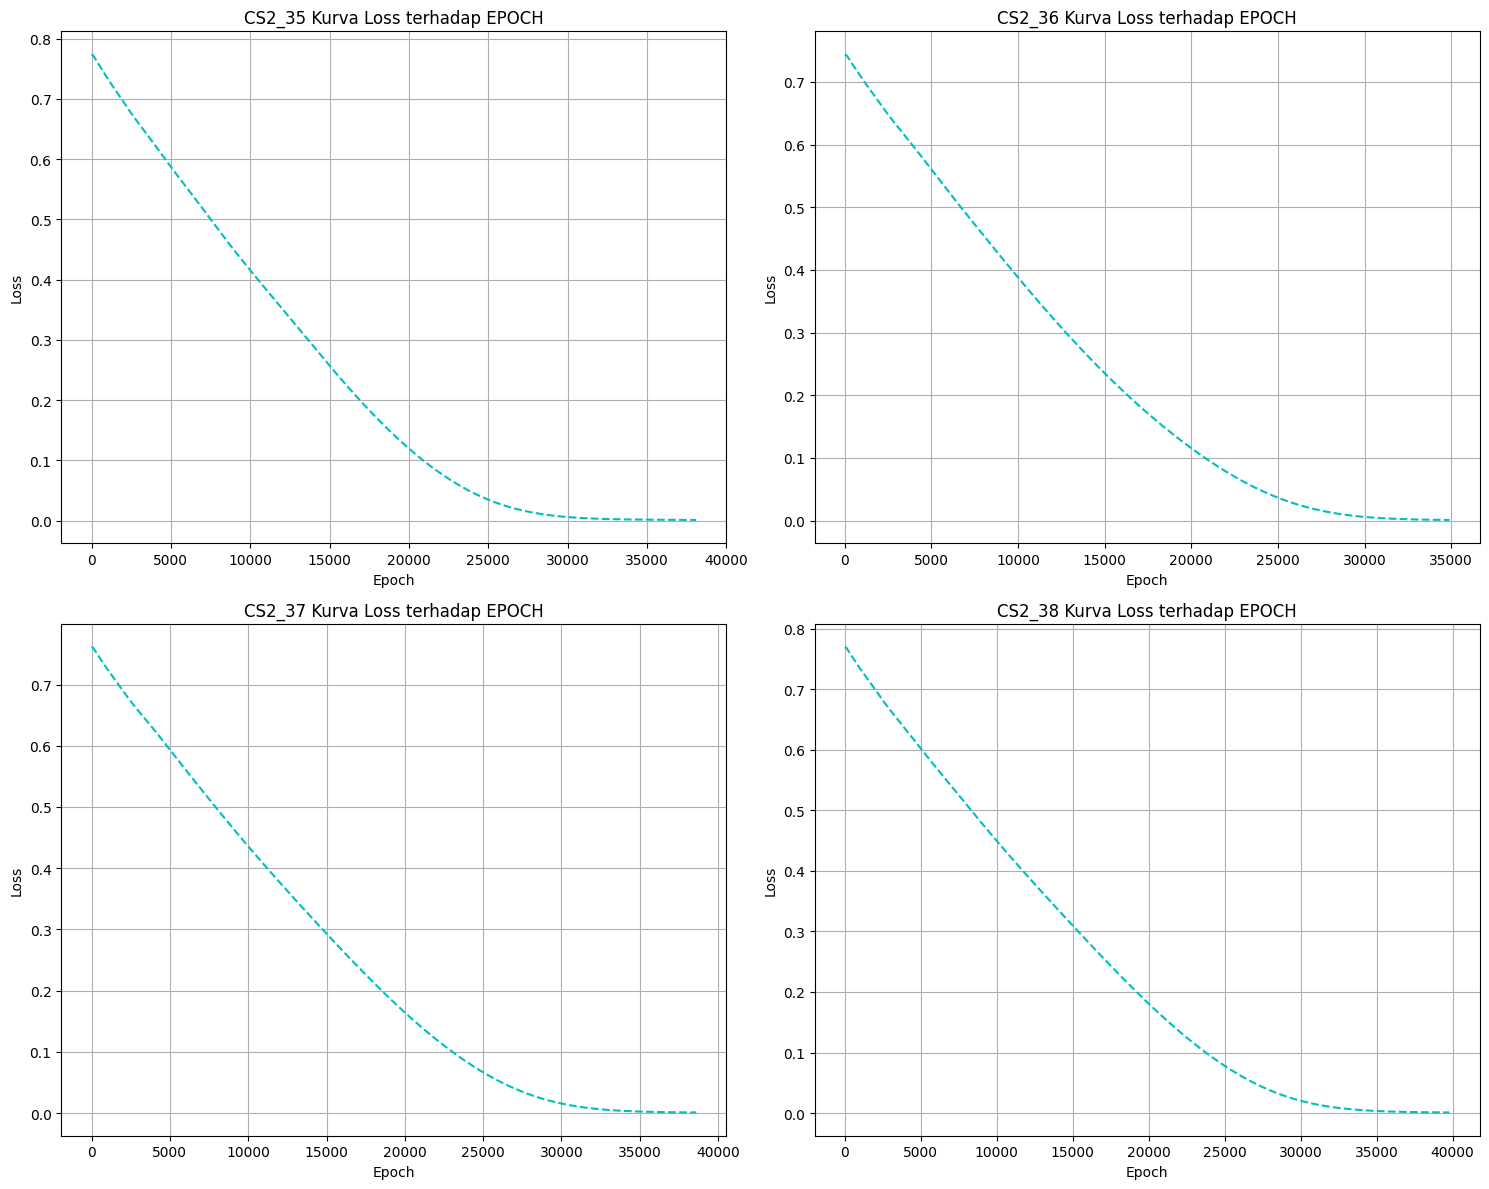

In [9]:
lr = 1e-2    # Learning Rate
k = 3
stop = 1e-3
epochs = 100000

fig, axs = plt.subplots(2, 2, figsize=(15, 12))  
axs = axs.flatten()

for i, name in enumerate(Battery_list):
    print(f'\nTraining on: {name}')
    setup_seed(seed=0)  

    df = Battery[name]
    x, y = np.array(df['cycle']), np.array(df['capacity'])

    model, loss_list = train_Gauss(data=np.c_[x, y], k=k, lr=lr, stop=stop, epochs=epochs, device=device)

    axs[i].plot(range(0, len(loss_list)*100, 100), loss_list, 'c--', label='Loss')
    axs[i].set_title(f'{name} Kurva Loss terhadap EPOCH')
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Loss')
    axs[i].grid(True)

plt.tight_layout()
plt.savefig("./Gambar/Kurva Loss terhadap EPOCH.png")
plt.show()

#### Tahap 4 : Menggunakan Multi-Layer Perceptron Neural Network (MLP) Model untuk Memodelkan SOH and RUL

In [10]:
def build_sequences(text, window_size):
    x, y = [], []
    for i in range(len(text) - window_size):
        sequence = text[i:i+window_size]
        target = text[i+1:i+1+window_size]
        x.append(sequence)
        y.append(target)
    return np.array(x), np.array(y)

def get_train_test(data_dict, name, window_size=8, train_ratio=0.):
    data_sequence = data_dict[name]['capacity']
    train_data, test_data = data_sequence[:window_size+1], data_sequence[window_size+1:]
    train_x, train_y = build_sequences(text=train_data, window_size=window_size)

    for k, v in data_dict.items():
        if k != name:
            data_x, data_y = build_sequences(text=v['capacity'], window_size=window_size)
            train_x = np.concatenate([train_x, data_x])
            train_y = np.concatenate([train_y, data_y])
            
    return train_x, train_y, list(train_data), list(test_data)

def evaluation(y_test, y_predict):
    r2 = r2_score(y_test, y_predict)
    mae = mean_absolute_error(y_test, y_predict)
    mse = mean_squared_error(y_test, y_predict)
    rmse = sqrt(mse)
    return mae, rmse, r2

def relative_error_MLP(y_test, y_predict, threshold):
    true_re, pred_re = len(y_test), 0
    for i in range(len(y_test)-1):
        if y_test[i] <= threshold >= y_test[i+1]:
            true_re = i - 1
            break
    for i in range(len(y_predict)-1):
        if y_predict[i] <= threshold:
            pred_re = i - 1
            break
    return abs(true_re - pred_re) / true_re

In [11]:
class Net_MLP(nn.Module):
    def __init__(self, feature_size=8, hidden_size=[16, 8]):
        super(Net_MLP, self).__init__()
        self.layer0 = nn.Linear(feature_size, hidden_size[0])
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(hidden_size[i], hidden_size[i+1]), nn.ReLU())
            for i in range(len(hidden_size) - 1)
        ])
        self.linear = nn.Linear(hidden_size[-1], 1)

    def forward(self, x):
        out = self.layer0(x)
        for layer in self.layers:
            out = layer(out)
        return self.linear(out)


In [12]:
def train_MLP(LR_MLP=0.01, feature_size_MLP=8, hidden_size_MLP=[16, 8], weight_decay_MLP=0.0, window_size_MLP=8, EPOCH_MLP=1000, seed=0):
    mae_list, rmse_list, re_list, rsquare_list = [], [], [], []
    result_list = []

    for i in range(4):
        name = Battery_list[i]
        train_x, train_y, train_data, test_data = get_train_test(Battery, name, window_size_MLP)

        print(f"[{name}] train_x: {train_x.shape}, train_y: {train_y.shape}")
        setup_seed(seed)
        model = Net_MLP(feature_size=feature_size_MLP, hidden_size=hidden_size_MLP).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=LR_MLP, weight_decay=weight_decay_MLP)
        criterion = nn.MSELoss()

        test_x = train_data.copy()
        loss_list, y_ = [0], []

        for epoch in range(EPOCH_MLP):
            X = torch.from_numpy(train_x.astype(np.float32) / Rated_Capacity).to(device)
            y = torch.from_numpy(train_y[:, -1].astype(np.float32) / Rated_Capacity).view(-1, 1).to(device)

            if X.shape[1] != feature_size_MLP:
                raise ValueError(f"Expected input feature size {feature_size_MLP}, but got {X.shape[1]}")

            output = model(X)
            loss = criterion(output, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if (epoch + 1) % 100 == 0:
                test_x = train_data.copy()
                point_list = []

                while len(test_x) - len(train_data) < len(test_data):
                    x_input = np.array(test_x[-feature_size_MLP:]).astype(np.float32) / Rated_Capacity
                    x = torch.from_numpy(x_input.reshape(1, -1)).to(device)
                    pred = model(x)
                    next_point = pred.detach().cpu().numpy()[0, 0] * Rated_Capacity
                    test_x.append(next_point)
                    point_list.append(next_point)

                y_.append(point_list)
                loss_list.append(loss.item())
                mae, rmse, rsquare = evaluation(y_test=test_data, y_predict=y_[-1])
                re = relative_error_MLP(y_test=test_data, y_predict=y_[-1], threshold=Rated_Capacity * 0.7)
                print(f'epoch:{epoch:<4d} | loss:{loss.item():<8.6f} | R2:{rsquare:<6.4f} | MAE:{mae:<6.4f} | RMSE:{rmse:<6.4f} | RE:{re:<6.4f}')

            if len(loss_list) > 1 and abs(loss_list[-2] - loss_list[-1]) < 1e-6:
                break

        mae, rmse, rsquare = evaluation(test_data, y_[-1])
        re = relative_error_MLP(test_data, y_[-1], threshold=Rated_Capacity * 0.7)
        mae_list.append(mae)
        rsquare_list.append(rsquare)
        rmse_list.append(rmse)
        re_list.append(re)
        result_list.append(y_[-1])

    return re_list, mae_list, rmse_list, rsquare_list, result_list


In [13]:
# Loop Training with Different Seeds
window_size = 8
Epoch = 1000
LR1 = 0.01
feature_size = window_size
hidden_size = [32, 16]
weight_decay = 0.0
Rated_Capacity = 1.1 # Kapasitas terukur baterai menurun 30%, dari 1,1 Ahr menjadi 0,77 Ahr, sehingga 1,1 menjadi standar End Of Life (EOF)

MAE, RMSE, RE, R2 = [], [], [], []

for seed in range(10):
    re_list, mae_list, rmse_list, rsquare_list, _ = train_MLP(
        LR_MLP=LR1,
        feature_size_MLP=feature_size,
        hidden_size_MLP=hidden_size,
        weight_decay_MLP=weight_decay,
        window_size_MLP=window_size,
        EPOCH_MLP=Epoch,
        seed=seed
    )
    R2.append(np.mean(np.array(rsquare_list)))
    RE.append(np.mean(np.array(re_list)))
    MAE.append(np.mean(np.array(mae_list)))
    RMSE.append(np.mean(np.array(rmse_list)))
    print('------------------------------------------------------------------')

print('R2:   mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(R2), np.std(R2)))
print('RE:   mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(RE), np.std(RE)))
print('MAE:  mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(MAE), np.std(MAE)))
print('RMSE: mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(RMSE), np.std(RMSE)))


[CS2_35] train_x: (2881, 8), train_y: (2881, 8)
epoch:99   | loss:0.000185 | R2:-2.1257 | MAE:0.2996 | RMSE:0.3669 | RE:0.4794
epoch:199  | loss:0.000177 | R2:0.8400 | MAE:0.0626 | RMSE:0.0830 | RE:0.0873
epoch:299  | loss:0.000174 | R2:0.8444 | MAE:0.0616 | RMSE:0.0819 | RE:0.0841
epoch:399  | loss:0.000172 | R2:0.8422 | MAE:0.0621 | RMSE:0.0824 | RE:0.0857
epoch:499  | loss:0.000169 | R2:0.8401 | MAE:0.0626 | RMSE:0.0830 | RE:0.0873
epoch:599  | loss:0.000166 | R2:0.8377 | MAE:0.0631 | RMSE:0.0836 | RE:0.0889
epoch:699  | loss:0.000163 | R2:0.8356 | MAE:0.0636 | RMSE:0.0841 | RE:0.0905
epoch:799  | loss:0.000159 | R2:0.8338 | MAE:0.0640 | RMSE:0.0846 | RE:0.0905
epoch:899  | loss:0.000156 | R2:0.8330 | MAE:0.0642 | RMSE:0.0848 | RE:0.0921
epoch:999  | loss:0.000153 | R2:0.8321 | MAE:0.0643 | RMSE:0.0850 | RE:0.0921
[CS2_36] train_x: (2827, 8), train_y: (2827, 8)
epoch:99   | loss:0.000219 | R2:0.1914 | MAE:0.1373 | RMSE:0.2326 | RE:1.0000
epoch:199  | loss:0.000183 | R2:0.9635 | MAE:

[CS2_35] train_x: (2881, 8), train_y: (2881, 8)
epoch:99   | loss:0.000171 | R2:0.2263 | MAE:0.1105 | RMSE:0.1825 | RE:1.0000
epoch:199  | loss:0.000153 | R2:0.8441 | MAE:0.0618 | RMSE:0.0819 | RE:0.0841
epoch:299  | loss:0.000152 | R2:0.8049 | MAE:0.0703 | RMSE:0.0917 | RE:0.1063
[CS2_36] train_x: (2827, 8), train_y: (2827, 8)
epoch:99   | loss:0.000244 | R2:0.2112 | MAE:0.1688 | RMSE:0.2297 | RE:1.0000
epoch:199  | loss:0.000157 | R2:0.3217 | MAE:0.1629 | RMSE:0.2130 | RE:0.3291
epoch:299  | loss:0.000155 | R2:0.3586 | MAE:0.1583 | RMSE:0.2071 | RE:0.3134
epoch:399  | loss:0.000154 | R2:0.3533 | MAE:0.1590 | RMSE:0.2080 | RE:0.3150
epoch:499  | loss:0.000152 | R2:0.3465 | MAE:0.1598 | RMSE:0.2091 | RE:0.3181
epoch:599  | loss:0.000150 | R2:0.3398 | MAE:0.1606 | RMSE:0.2101 | RE:0.3213
epoch:699  | loss:0.000148 | R2:0.3332 | MAE:0.1614 | RMSE:0.2112 | RE:0.3244
epoch:799  | loss:0.000146 | R2:0.3264 | MAE:0.1622 | RMSE:0.2123 | RE:0.3276
epoch:899  | loss:0.000144 | R2:0.3202 | MAE:0

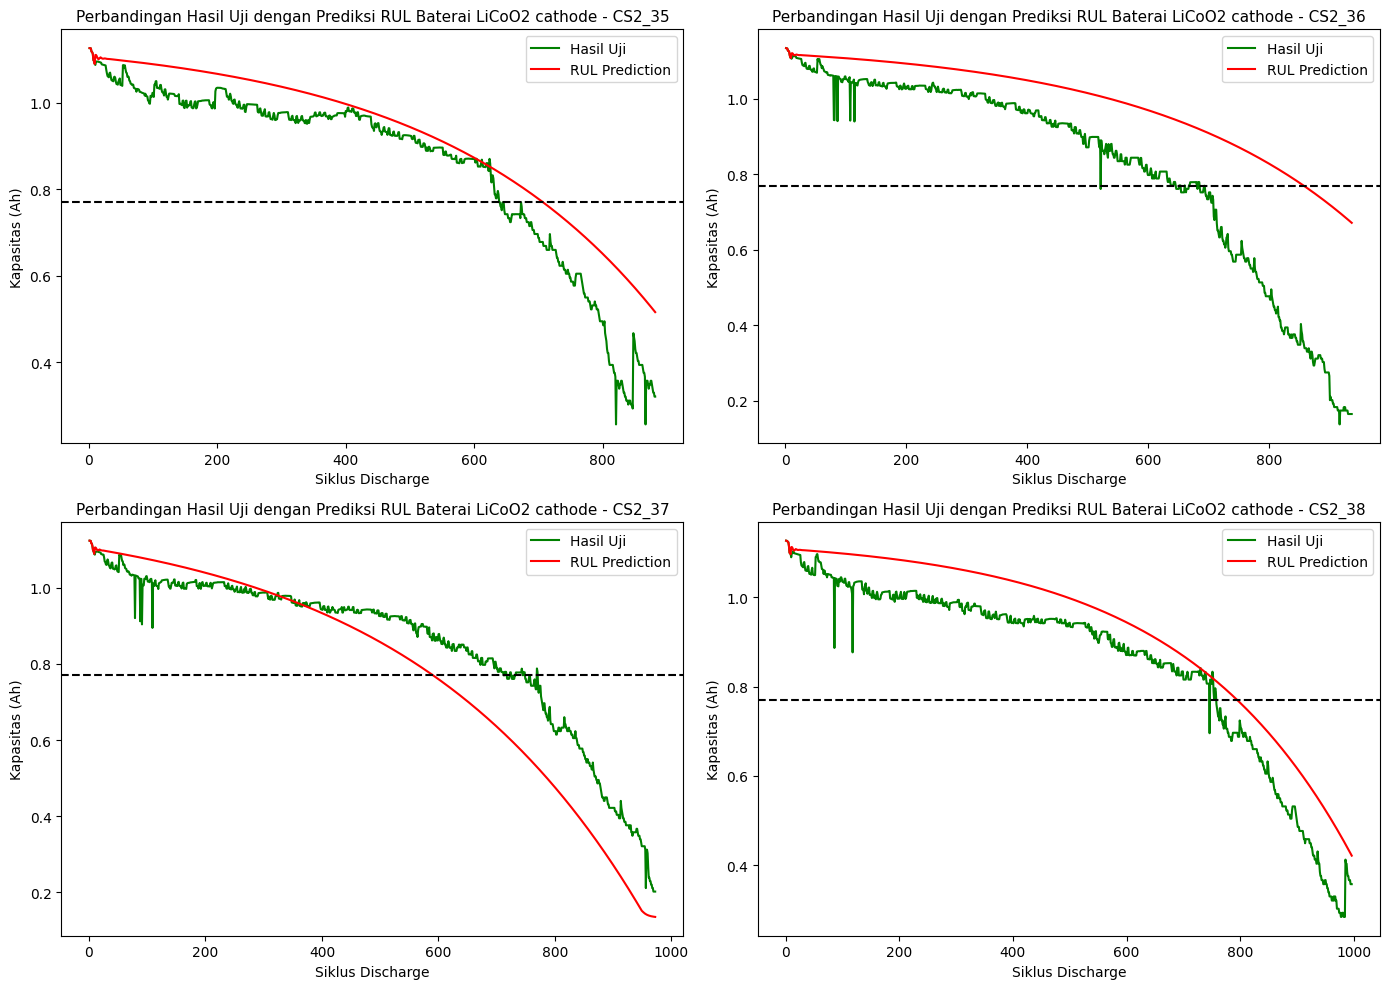

In [14]:
seed = 6
_, _, _, _, result_list = train_MLP(
    LR_MLP=LR1,
    feature_size_MLP=feature_size,
    hidden_size_MLP=hidden_size,
    weight_decay_MLP=weight_decay,
    window_size_MLP=window_size,
    EPOCH_MLP=Epoch,
    seed=seed
)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()

for i in range(4):
    name = Battery_list[i]
    train_x, train_y, train_data, test_data = get_train_test(Battery, name, window_size)

    prediction = train_data[:window_size+1].copy()
    prediction.extend(result_list[i])

    battery = Battery[name]
    axs[i].plot(battery['cycle'], battery['capacity'], 'g-', label='Hasil Uji')
    axs[i].plot(battery['cycle'], prediction, 'r-', label='RUL Prediction')
    axs[i].axhline(y=Rated_Capacity * 0.7, color='black', linestyle='--')
    axs[i].set_title('Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode - ' + name, fontsize=11)
    axs[i].set_xlabel('Siklus Discharge')
    axs[i].set_ylabel('Kapasitas (Ah)')
    axs[i].legend()

plt.tight_layout()
plt.savefig("./Gambar/SOH & RUL (MLP).png")
plt.show()


#### Tahap 5 : Memakai Recurrent Neural Networks (RNN), Long Short-Term Memory (LSTM), dan Gated Recurrent Unit (GRU) untuk Memodelkan SOH and RUL 


In [15]:
# Data Preparation & Evaluation
def build_instances(sequence, window_size):
    x, y = [], []
    for i in range(len(sequence) - window_size):
        features = sequence[i:i+window_size]
        target = sequence[i+window_size]
        x.append(features)
        y.append(target)
    return np.array(x).astype(np.float32), np.array(y).astype(np.float32)

def get_train_test(data_dict, name, window_size=8):
    data_sequence = data_dict[name]['capacity']
    train_data, test_data = data_sequence[:window_size+1], data_sequence[window_size+1:]
    train_x, train_y = build_instances(train_data, window_size)
    for k, v in data_dict.items():
        if k != name:
            data_x, data_y = build_instances(v['capacity'], window_size)
            train_x, train_y = np.r_[train_x, data_x], np.r_[train_y, data_y]
    return train_x, train_y, list(train_data), list(test_data)

def relative_error(y_test, y_predict, threshold):
    true_re, pred_re = len(y_test), 0
    for i in range(len(y_test)-1):
        if y_test[i] <= threshold >= y_test[i+1]:
            true_re = i - 1
            break
    for i in range(len(y_predict)-1):
        if y_predict[i] <= threshold:
            pred_re = i - 1
            break
    return abs(true_re - pred_re)/true_re if abs(true_re - pred_re)/true_re <= 1 else 1

def evaluation(y_test, y_predict):
    r2 = r2_score(y_test, y_predict)
    rmse = sqrt(mean_squared_error(y_test, y_predict))
    mae = mean_absolute_error(y_test, y_predict)
    return mae, rmse, r2

In [16]:
class Net_RNN_LSTM_GRU(nn.Module):
    def __init__(self, hidden_dim=8, num_layers=1, mode='RNN'): # RNN or LSTM or GRU
        super(Net_RNN_LSTM_GRU, self).__init__()
        self.hidden_dim = hidden_dim
        if mode == 'LSTM':
            self.cell = nn.LSTM(input_size=1, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
        elif mode == 'RNN':
            self.cell = nn.RNN(input_size=1, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
        elif mode == 'GRU':
            self.cell = nn.GRU(input_size=1, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
        else:
            raise ValueError("Mode must be either 'LSTM', 'RNN', or 'GRU'")
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.cell(x)
        out = out[:, -1, :]
        out = self.linear(out)
        return out

In [17]:
# Training Loop
def train_model(lr, feature_size, hidden_dim=64, num_layers=2, weight_decay=0.0, mode='RNN', # RNN or LSTM
                epochs=100, seed=0, device='cpu', metric='rmse'):
    score_list, result_list = [], []
    setup_seed(seed)

    for i in range(4):
        name = Battery_list[i]
        train_x, train_y, train_data, test_data = get_train_test(Battery, name, feature_size)
        test_sequence = train_data + test_data
        test_x, test_y = build_instances(test_sequence, feature_size)

        model = Net_RNN_LSTM_GRU(hidden_dim=hidden_dim, num_layers=num_layers, mode=mode).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        criterion = nn.MSELoss()

        y_ = []
        best_score = 1

        for epoch in range(epochs):
            X = np.reshape(train_x / Rated_Capacity, (-1, feature_size, 1))
            y = np.reshape(train_y / Rated_Capacity, (-1, 1))
            X, y = torch.from_numpy(X).to(device), torch.from_numpy(y).to(device)

            output = model(X).reshape(-1, 1)
            loss = criterion(output, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if (epoch + 1) % 10 == 0:
                x = np.reshape(test_x / Rated_Capacity, (-1, feature_size, 1))
                x = torch.from_numpy(x).to(device)
                pred = model(x).data.cpu().numpy().reshape(-1) * Rated_Capacity
                y_.append(pred)

                mae, rmse, r2 = evaluation(test_y, y_[-1])
                re = relative_error(test_y, y_[-1], Rated_Capacity * 0.7)

                score = [re, mae, rmse, r2]
                if loss < 1e-3 and best_score < score[2]:
                    break
                best_score = score[2]

        score_list.append(score)
        result_list.append(train_data.copy()[:-1] + list(y_[-1]))

    return score_list, result_list


In [18]:
# Multiple Seeds Evaluation - Untuk Final
# Single Seed digunakan untuk trial test.
feature_size = 64
EPOCH = 100
lr = 0.001 # Learning Rate
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
mode = 'RNN'
Rated_Capacity = 1.1 # Kapasitas terukur baterai menurun 30%, dari 1,1 Ahr menjadi 0,77 Ahr, sehingga 1,1 menjadi standar End Of Life (EOF)
metric = 'rmse'
device = 'cpu'

SCORE = []
for seed in tqdm(range(4)):
    print('seed: ', seed)
    score_list, _ = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim, num_layers=num_layers, 
                         weight_decay=weight_decay, mode=mode, epochs=EPOCH, seed=seed, device=device, metric='rmse')
    
    print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
    print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
    print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
    print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")
    for s in score_list:
        SCORE.append(s)
    print('------------------------------------------------------------------')

  0%|          | 0/4 [00:00<?, ?it/s]

seed:  0
[BT1]      RE : 0.081739 ,  MAE : 0.056624 ,  RMSE : 0.071949 ,  R2 : 0.878392
[BT2]      RE : 0.005172 ,  MAE : 0.016875 ,  RMSE : 0.027900 ,  R2 : 0.988234
[BT3]      RE : 0.069124 ,  MAE : 0.015080 ,  RMSE : 0.020055 ,  R2 : 0.990482
[BT4]      RE : 0.008671 ,  MAE : 0.019447 ,  RMSE : 0.033364 ,  R2 : 0.972611
------------------------------------------------------------------
seed:  1
[BT1]      RE : 0.012174 ,  MAE : 0.020368 ,  RMSE : 0.024849 ,  R2 : 0.985494
[BT2]      RE : 0.022414 ,  MAE : 0.015204 ,  RMSE : 0.021655 ,  R2 : 0.992912
[BT3]      RE : 0.009217 ,  MAE : 0.018061 ,  RMSE : 0.029880 ,  R2 : 0.978871
[BT4]      RE : 0.005780 ,  MAE : 0.008817 ,  RMSE : 0.014920 ,  R2 : 0.994523
------------------------------------------------------------------
seed:  2
[BT1]      RE : 0.006957 ,  MAE : 0.011234 ,  RMSE : 0.020125 ,  R2 : 0.990486
[BT2]      RE : 0.018966 ,  MAE : 0.014223 ,  RMSE : 0.019436 ,  R2 : 0.994290
[BT3]      RE : 0.070661 ,  MAE : 0.018187 ,  RMS

In [19]:
# Single Training Run: RNN
seed = 2
feature_size = 64
epochs = 100
lr = 0.001
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
Rated_Capacity = 1.1
mode = 'RNN'
metric = 'rmse'
device = 'cpu'

print('seed:', seed)
score_list, prediction_list = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim,
                                          num_layers=num_layers, weight_decay=weight_decay,
                                          mode=mode, epochs=epochs, seed=seed, device=device,
                                          metric=metric)

print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")


seed: 2
[BT1]      RE : 0.006957 ,  MAE : 0.011234 ,  RMSE : 0.020125 ,  R2 : 0.990486
[BT2]      RE : 0.018966 ,  MAE : 0.014223 ,  RMSE : 0.019436 ,  R2 : 0.994290
[BT3]      RE : 0.070661 ,  MAE : 0.018187 ,  RMSE : 0.022757 ,  R2 : 0.987744
[BT4]      RE : 0.008671 ,  MAE : 0.012566 ,  RMSE : 0.017876 ,  R2 : 0.992137


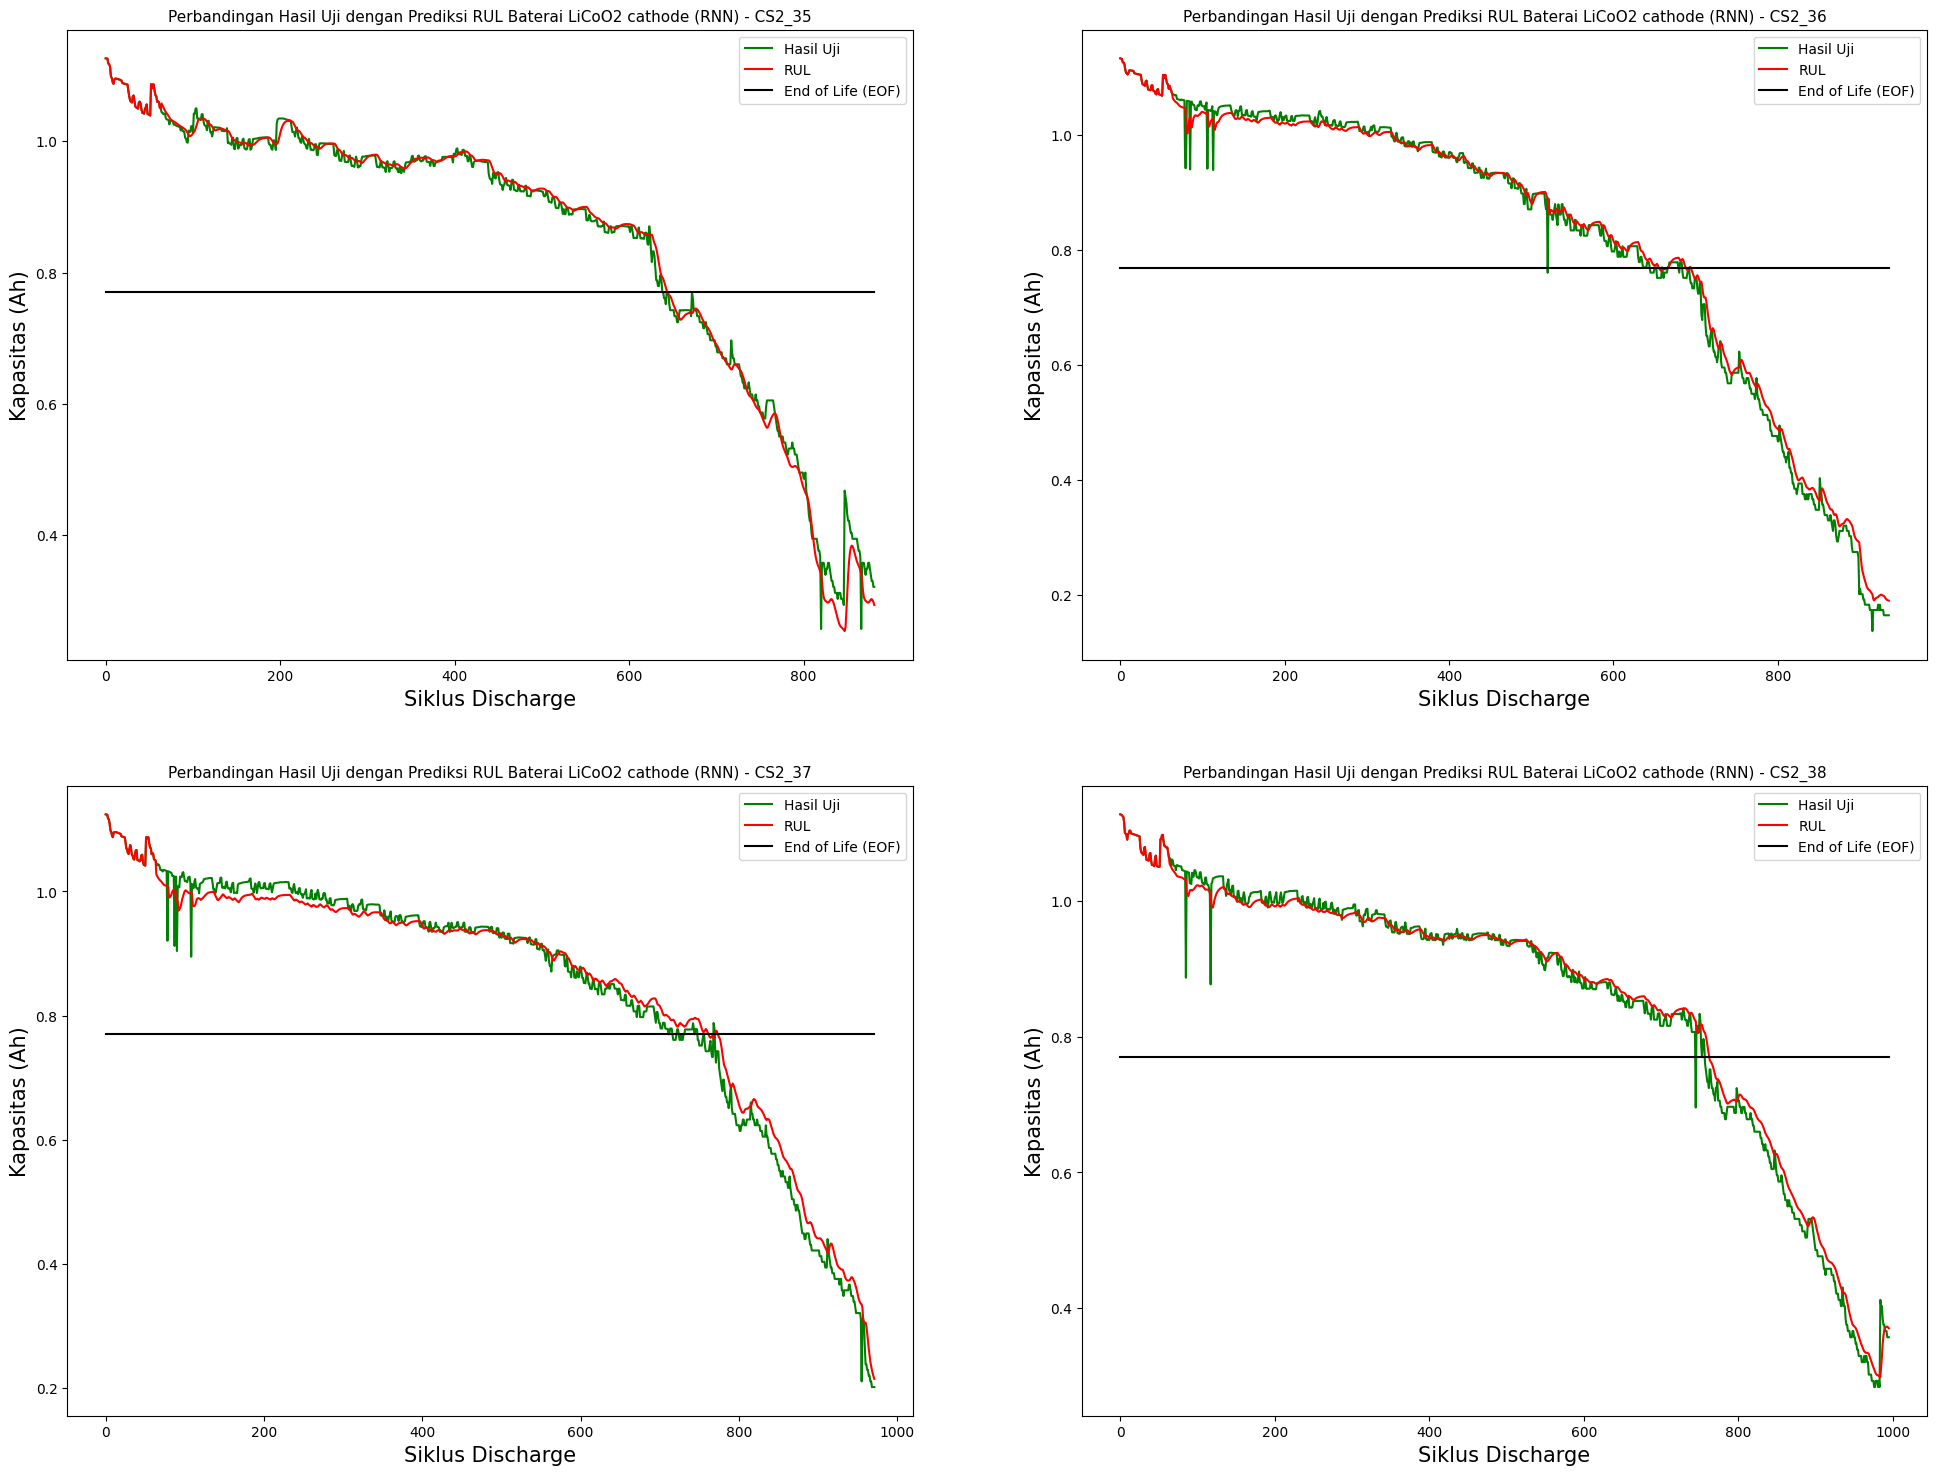

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(24, 18))

for i in range(2):
    for j in range(2):
        t = 2 * i + j
        battery_name = Battery_list[t]
        test_data = Battery[battery_name]['capacity']
        predict_data = prediction_list[t]
        score_data = score_list[t]
        x = list(range(len(test_data)))
        threshold = [Rated_Capacity * 0.7] * len(test_data)

        ax[i][j].plot(x, test_data, 'g', label='Hasil Uji')
        ax[i][j].plot(x, predict_data, 'r', label='RUL')
        ax[i][j].plot(x, threshold, 'black', ls='-', label='End of Life (EOF)')
        ax[i][j].legend()
        ax[i][j].set_xlabel('Siklus Discharge', fontsize=15)
        ax[i][j].set_ylabel('Kapasitas (Ah)', fontsize=15)
        ax[i][j].set_title(f'Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode (RNN) - {battery_name}', fontsize=11)

plt.savefig("./Gambar/SOH & RUL (RNN).png")
plt.show()

seed: 2
[BT1]      RE : 0.154783 ,  MAE : 0.084456 ,  RMSE : 0.114105 ,  R2 : 0.694142
[BT2]      RE : 0.124138 ,  MAE : 0.104510 ,  RMSE : 0.138611 ,  R2 : 0.709581
[BT3]      RE : 0.099846 ,  MAE : 0.076830 ,  RMSE : 0.099433 ,  R2 : 0.766015
[BT4]      RE : 0.028902 ,  MAE : 0.057193 ,  RMSE : 0.080235 ,  R2 : 0.841606


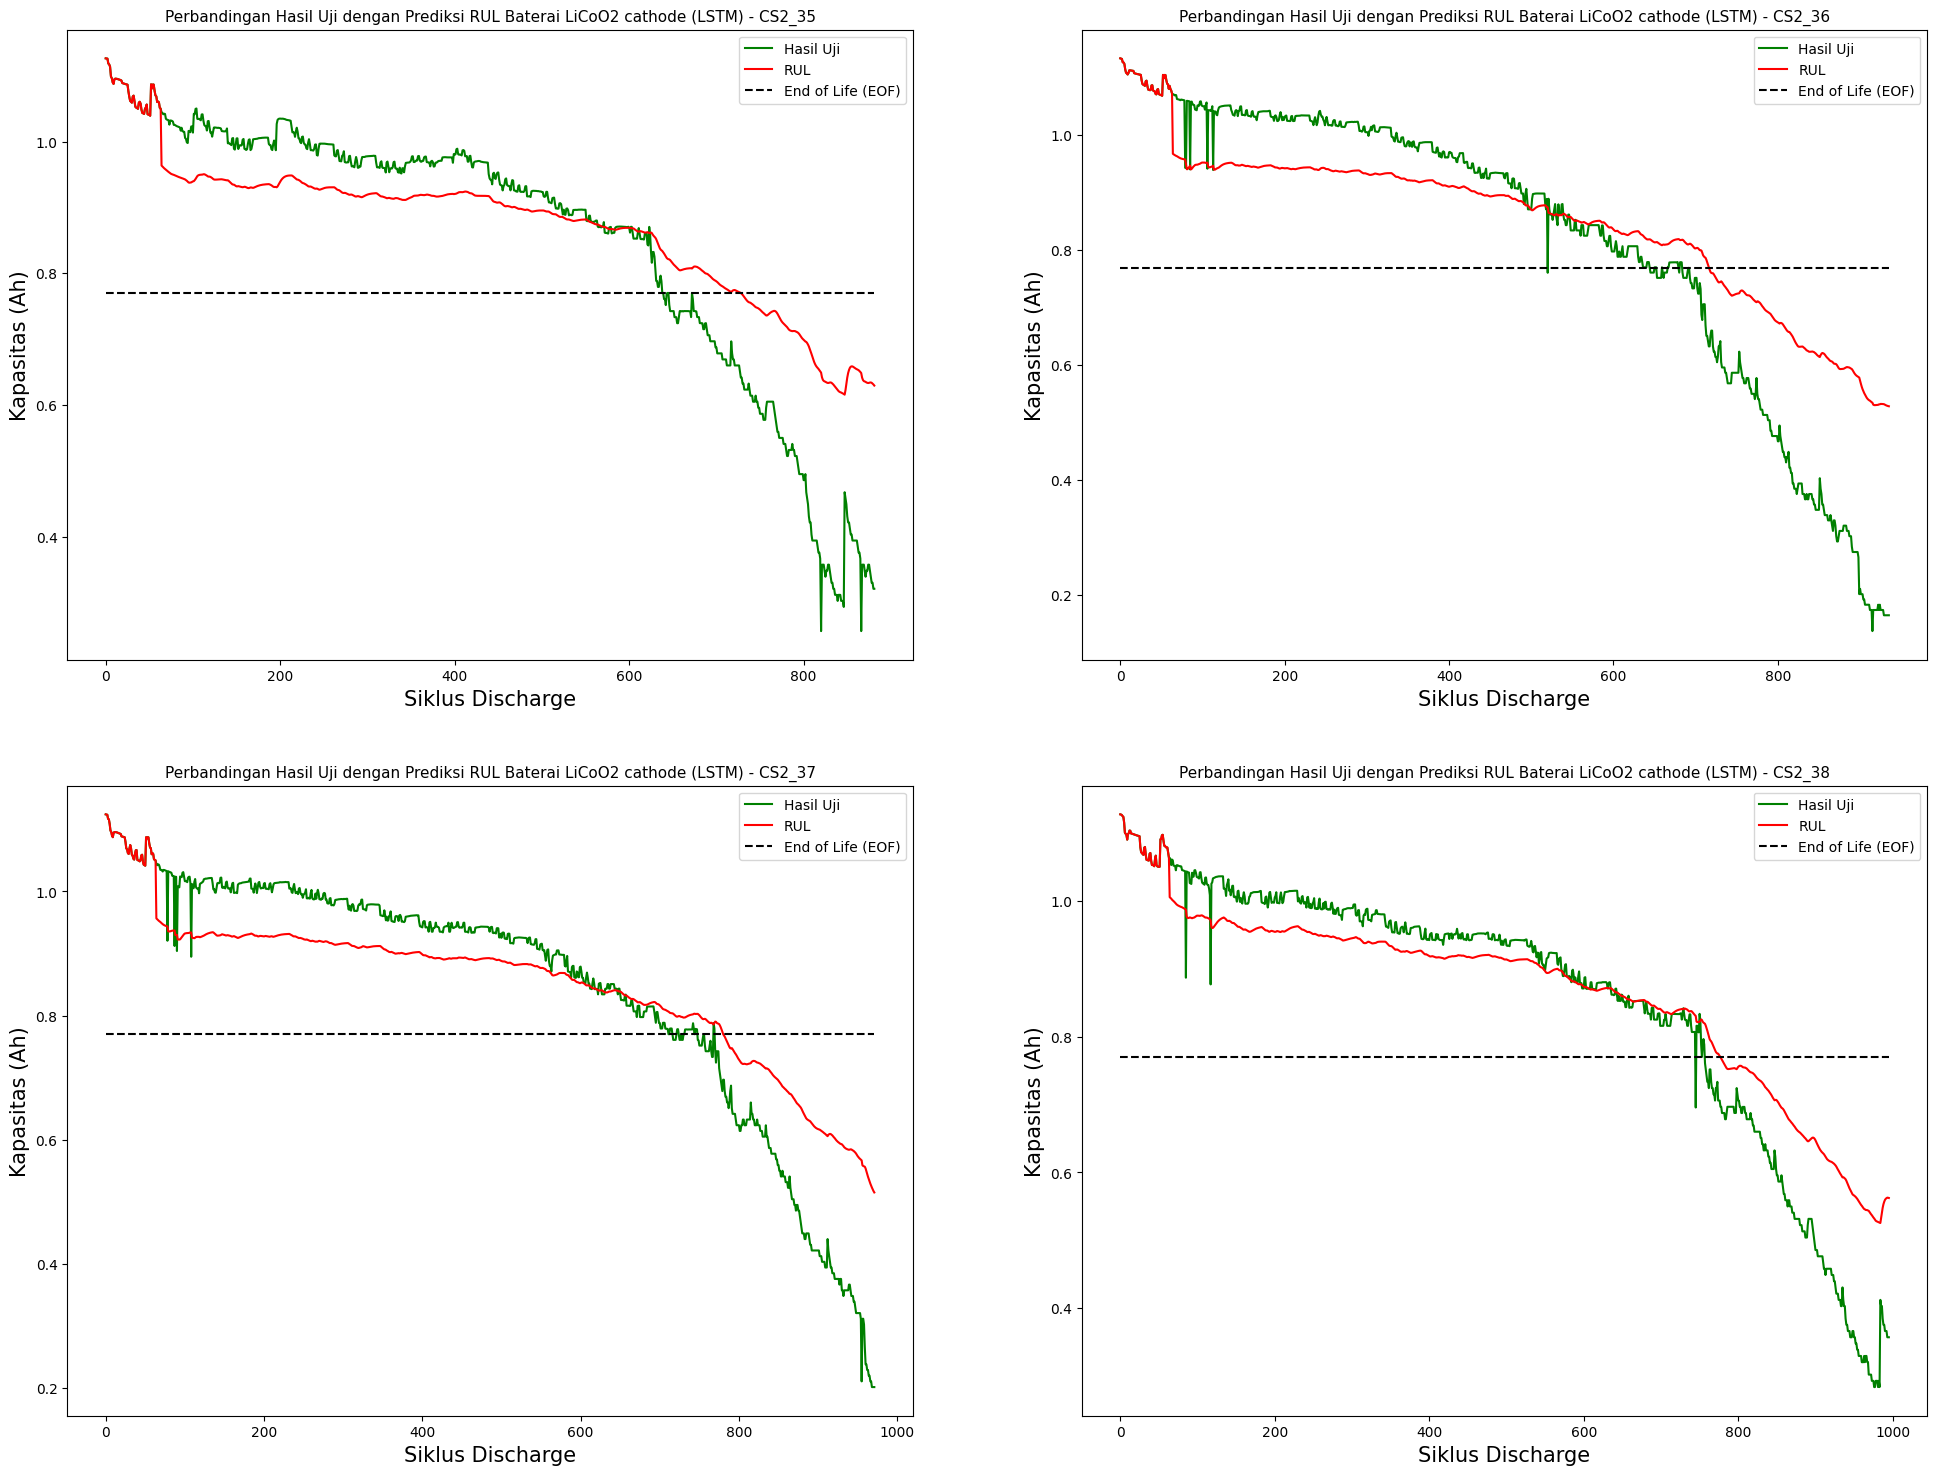

In [21]:
# Single Training Run: LSTM
seed = 2
feature_size = 64
epochs = 100
lr = 0.001
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
Rated_Capacity = 1.1
mode = 'LSTM'
metric = 'rmse'
device = 'cpu'

print('seed:', seed)
score_list, prediction_list = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim,
                                          num_layers=num_layers, weight_decay=weight_decay,
                                          mode=mode, epochs=epochs, seed=seed, device=device,
                                          metric=metric)

print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")

fig, ax = plt.subplots(2, 2, figsize=(24, 18))

for i in range(2):
    for j in range(2):
        t = 2 * i + j
        battery_name = Battery_list[t]
        test_data = Battery[battery_name]['capacity']
        predict_data = prediction_list[t]
        score_data = score_list[t]
        x = list(range(len(test_data)))
        threshold = [Rated_Capacity * 0.7] * len(test_data)

        ax[i][j].plot(x, test_data, 'g', label='Hasil Uji')
        ax[i][j].plot(x, predict_data, 'r', label='RUL')
        ax[i][j].plot(x, threshold, 'black', ls='--', label='End of Life (EOF)')
        ax[i][j].legend()
        ax[i][j].set_xlabel('Siklus Discharge', fontsize=15)
        ax[i][j].set_ylabel('Kapasitas (Ah)', fontsize=15)
        ax[i][j].set_title(f'Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode (LSTM) - {battery_name}', fontsize=11)

plt.savefig("./Gambar/SOH & RUL (LSTM).png")
plt.show()


seed: 2
[BT1]      RE : 0.081739 ,  MAE : 0.064933 ,  RMSE : 0.081917 ,  R2 : 0.842363
[BT2]      RE : 0.125862 ,  MAE : 0.122757 ,  RMSE : 0.159645 ,  R2 : 0.614754
[BT3]      RE : 0.098310 ,  MAE : 0.078773 ,  RMSE : 0.102307 ,  R2 : 0.752297
[BT4]      RE : 0.027457 ,  MAE : 0.062551 ,  RMSE : 0.081750 ,  R2 : 0.835568


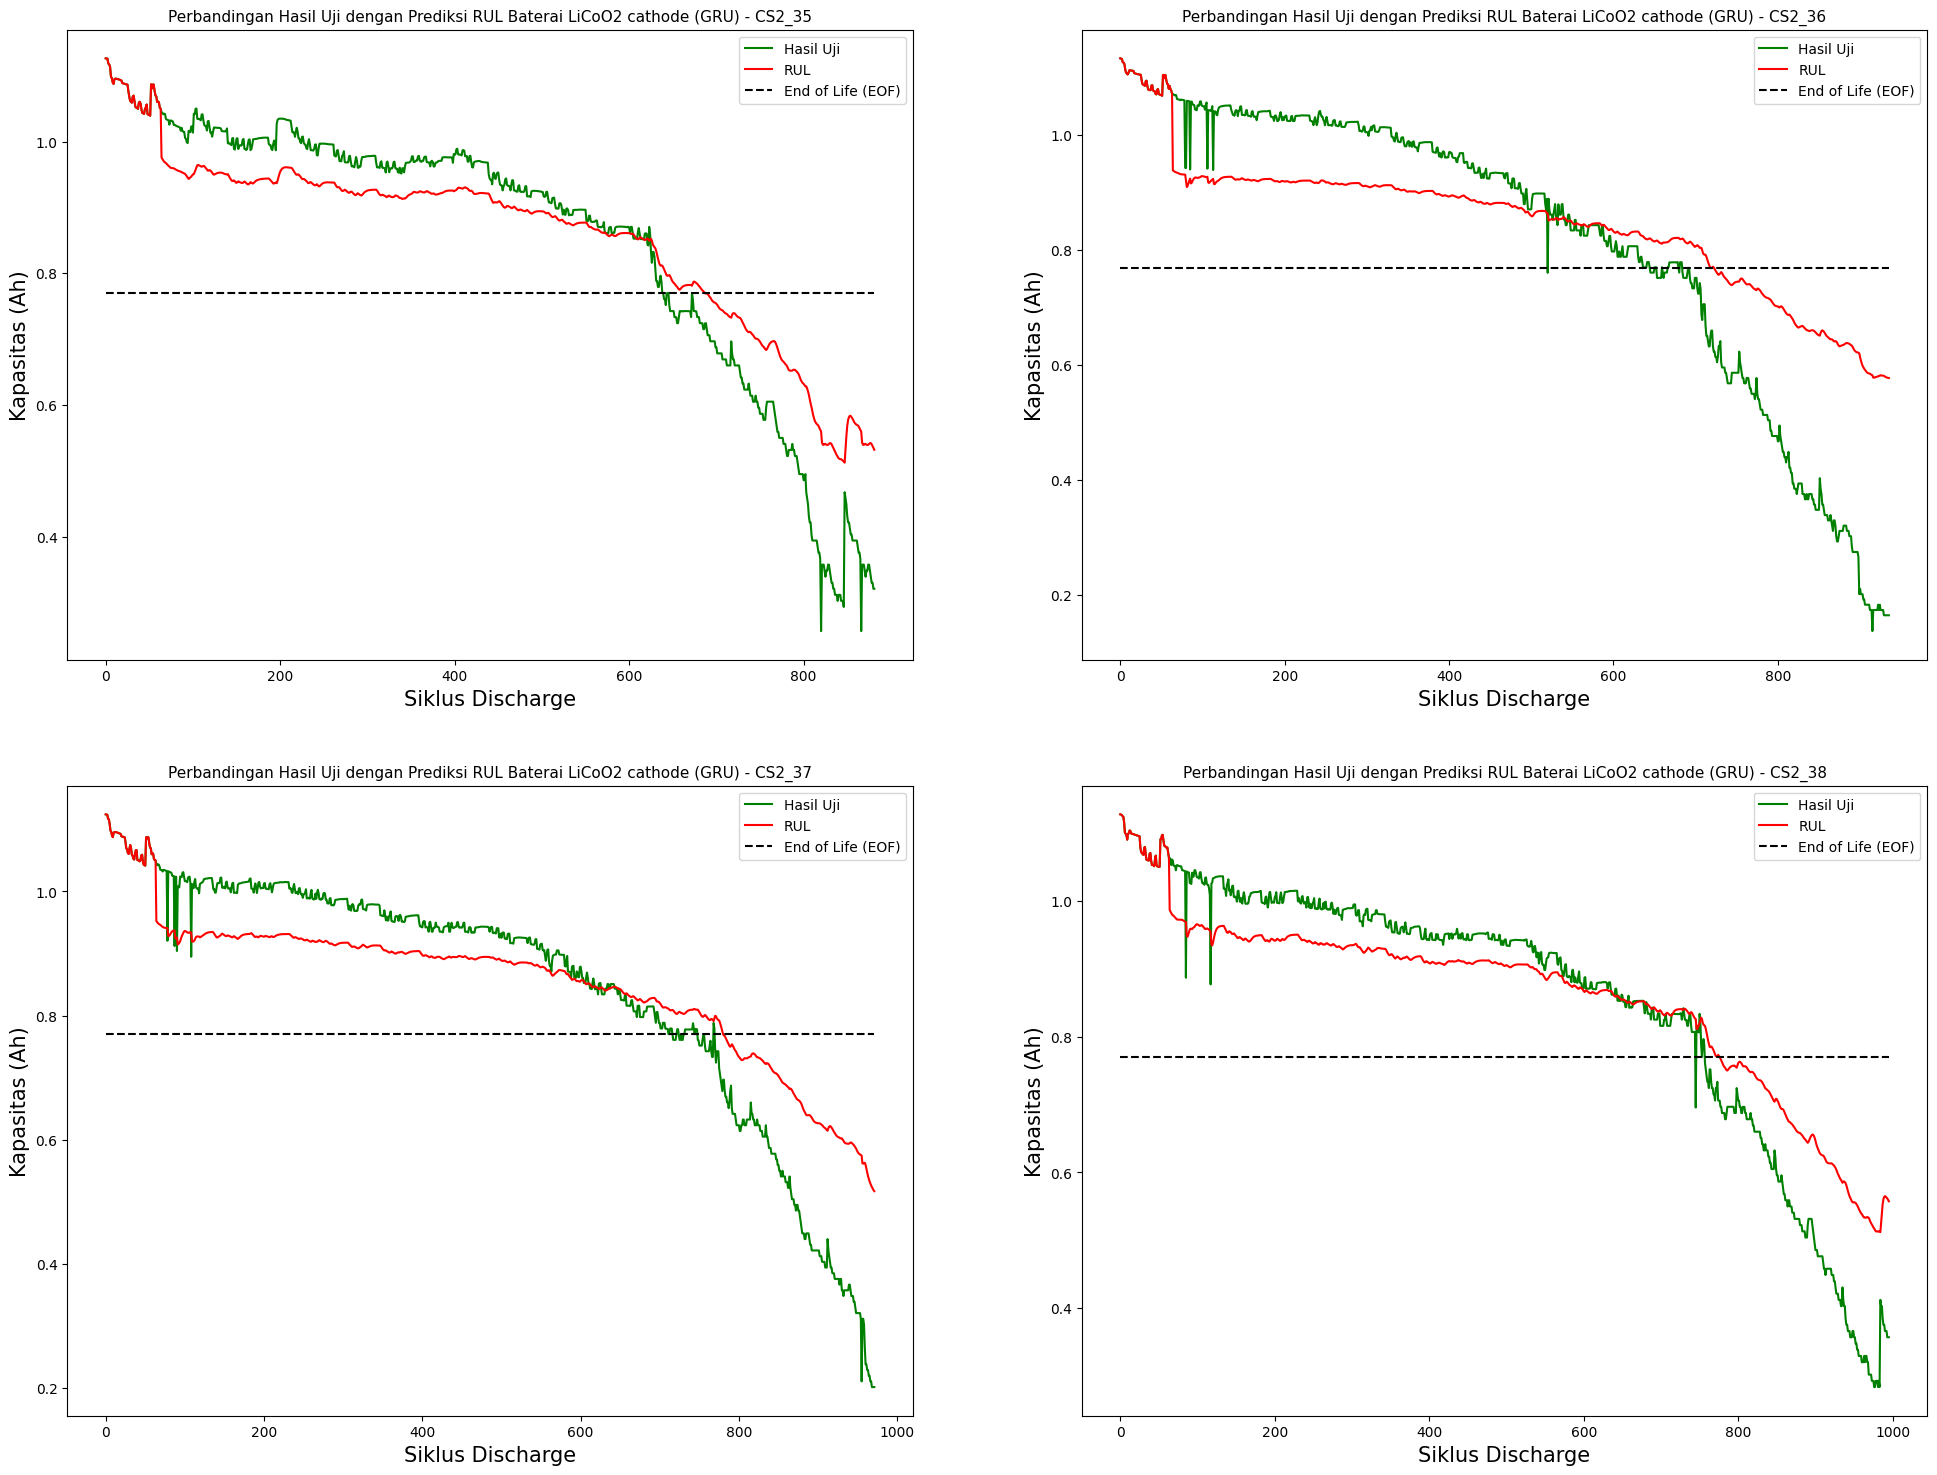

In [22]:
# Single Training Run: GRU
seed = 2
feature_size = 64
epochs = 100
lr = 0.001
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
Rated_Capacity = 1.1
mode = 'GRU'
metric = 'rmse'
device = 'cpu'

print('seed:', seed)
score_list, prediction_list = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim,
                                          num_layers=num_layers, weight_decay=weight_decay,
                                          mode=mode, epochs=epochs, seed=seed, device=device,
                                          metric=metric)

print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")

fig, ax = plt.subplots(2, 2, figsize=(24, 18))

for i in range(2):
    for j in range(2):
        t = 2 * i + j
        battery_name = Battery_list[t]
        test_data = Battery[battery_name]['capacity']
        predict_data = prediction_list[t]
        score_data = score_list[t]
        x = list(range(len(test_data)))
        threshold = [Rated_Capacity * 0.7] * len(test_data)

        ax[i][j].plot(x, test_data, 'g', label='Hasil Uji')
        ax[i][j].plot(x, predict_data, 'r', label='RUL')
        ax[i][j].plot(x, threshold, 'black', ls='--', label='End of Life (EOF)')
        ax[i][j].legend()
        ax[i][j].set_xlabel('Siklus Discharge', fontsize=15)
        ax[i][j].set_ylabel('Kapasitas (Ah)', fontsize=15)
        ax[i][j].set_title(f'Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode (GRU) - {battery_name}', fontsize=11)

plt.savefig("./Gambar/SOH & RUL (GRU).png")
plt.show()
